<a href="https://colab.research.google.com/github/ButenkoYuliia/diabetes-readmission-analysis/blob/main/notebooks/diabetes_readmission_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# 1. Авторизация в Google (откроется окно, разрешите доступ)
from google.colab import auth
auth.authenticate_user()

# 2. Библиотеки
import pandas as pd
from google.cloud import bigquery

# 3. Подключаемся к нашему проекту
client = bigquery.Client(project='medical-analytics-511709')

# 4. Загружаем чистую таблицу в DataFrame
query = """
SELECT *
FROM `medical-analytics-511709.diabetes_readmission.clean_diabetic_data`
"""
df = client.query(query).to_dataframe()

# 5. Проверка
print(df.shape)
display(df.head())

(99340, 50)


,encounter_id,patient_nbr,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,...,change,diabetesMed,readmitted,race,payer_code,medical_specialty,diag_1,diag_2,diag_3,readmitted_30d
0,2430276,69318126,Male,[70-80),6,1,7,7,82,2,...,No,No,NO,Caucasian,Unknown,Unknown,427,228,529,0
1,2473188,981198,Female,[60-70),6,25,1,5,47,3,...,No,Yes,>30,Caucasian,Unknown,Nephrology,250.4,403,276,0
2,3051324,42867,Male,[40-50),2,6,4,12,76,6,...,Ch,Yes,>30,Caucasian,Unknown,Unknown,410,428,426,0
3,3393054,1552221,Female,[70-80),6,25,4,7,1,0,...,No,Yes,NO,Caucasian,Unknown,Psychiatry,296,293,780,0
4,3773286,5985369,Male,[70-80),6,25,4,10,63,3,...,No,No,NO,Caucasian,Unknown,Orthopedics-Reconstructive,996,415,292,0


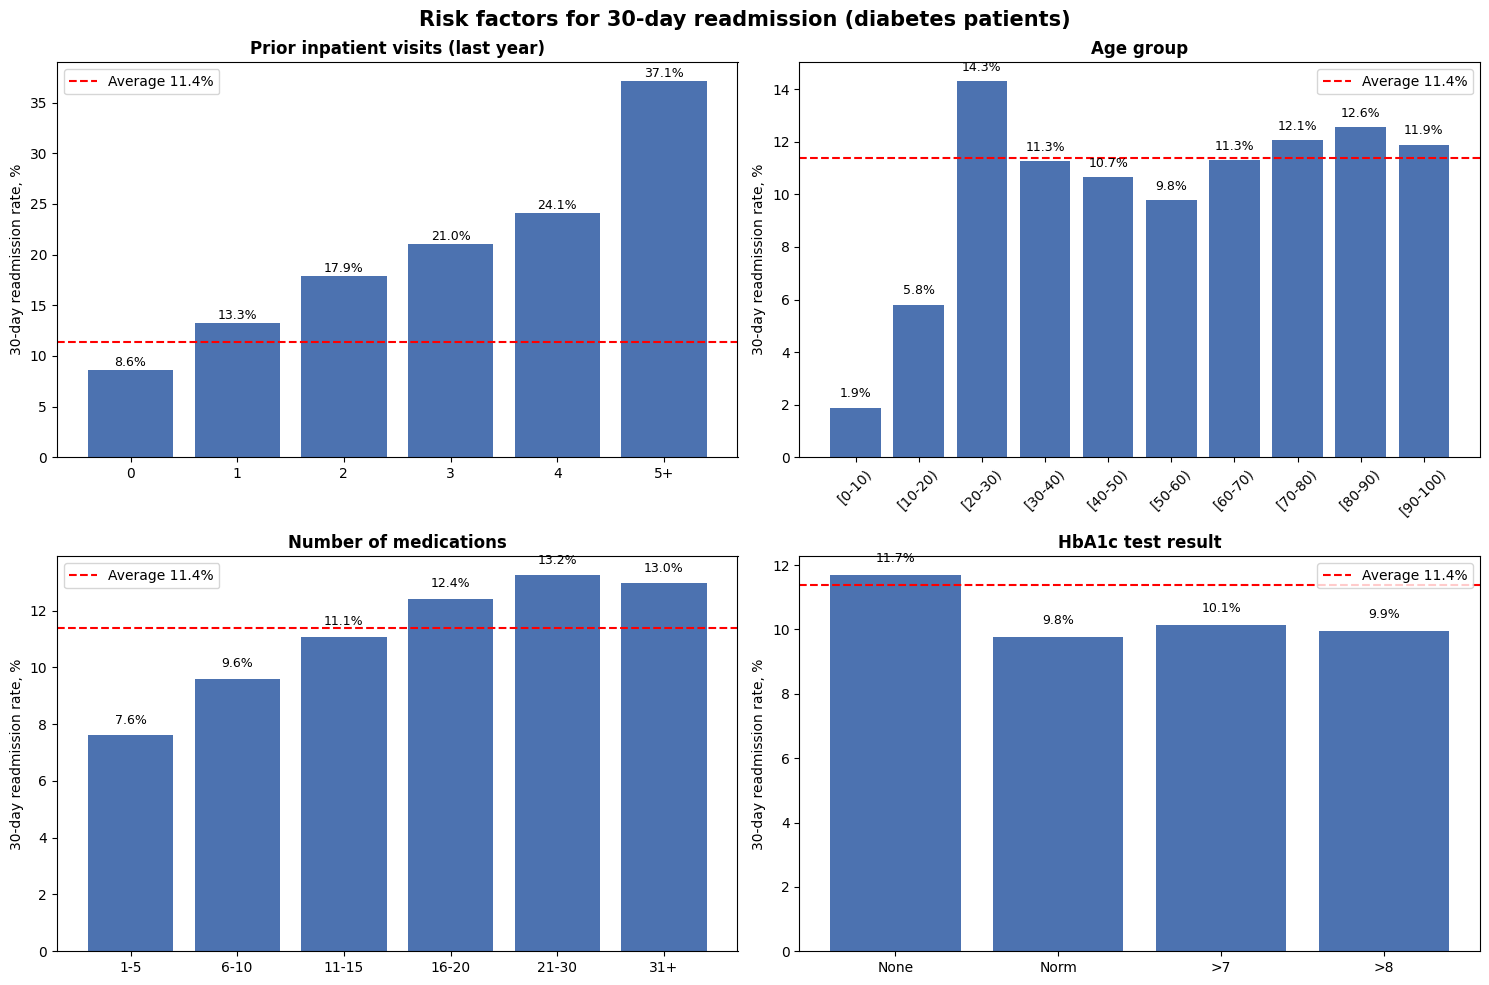

In [3]:
import matplotlib.pyplot as plt

# Базовый уровень: средний % повторных госпитализаций
baseline = df['readmitted_30d'].mean() * 100

# Группы, как в SQL
df['prior_inpatient'] = df['number_inpatient'].clip(upper=5).astype(str).replace('5', '5+')
df['med_group'] = pd.cut(df['num_medications'],
                         bins=[0, 5, 10, 15, 20, 30, 1000],
                         labels=['1-5', '6-10', '11-15', '16-20', '21-30', '31+'])

# Функция-шаблон для одного графика
def plot_rate(col, title, ax, order=None):
    rates = df.groupby(col, observed=True)['readmitted_30d'].mean() * 100
    if order:
        rates = rates.reindex(order)
    ax.bar(rates.index.astype(str), rates.values, color='#4C72B0')
    ax.axhline(baseline, color='red', linestyle='--', label=f'Average {baseline:.1f}%')
    for i, v in enumerate(rates.values):
        ax.text(i, v + 0.4, f'{v:.1f}%', ha='center', fontsize=9)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_ylabel('30-day readmission rate, %')
    ax.legend()

# 4 графика на одном рисунке (2 x 2)
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
plot_rate('prior_inpatient', 'Prior inpatient visits (last year)', axes[0, 0],
          order=['0', '1', '2', '3', '4', '5+'])
plot_rate('age', 'Age group', axes[0, 1])
plot_rate('med_group', 'Number of medications', axes[1, 0])
plot_rate('A1Cresult', 'HbA1c test result', axes[1, 1],
          order=['None', 'Norm', '>7', '>8'])
axes[0, 1].tick_params(axis='x', rotation=45)

plt.suptitle('Risk factors for 30-day readmission (diabetes patients)', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('risk_factors.png', dpi=150, bbox_inches='tight')
plt.show()

In [4]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, classification_report

# 1. Признаки (то, что известно на момент выписки)
m = df.copy()
m['age_num']         = m['age'].str.extract(r'\[(\d+)')[0].astype(int)
m['discharge_home']  = (m['discharge_disposition_id'] == 1).astype(int)
m['discharge_snf']   = (m['discharge_disposition_id'] == 3).astype(int)
m['discharge_rehab'] = (m['discharge_disposition_id'] == 22).astype(int)
m['a1c_tested']      = (m['A1Cresult'] != 'None').astype(int)
m['insulin_used']    = (m['insulin'] != 'No').astype(int)
m['med_changed']     = (m['change'] == 'Ch').astype(int)
m['diabetes_med']    = (m['diabetesMed'] == 'Yes').astype(int)

features = ['number_inpatient', 'number_emergency', 'number_outpatient',
            'num_medications', 'time_in_hospital', 'num_lab_procedures',
            'number_diagnoses', 'age_num', 'discharge_home', 'discharge_snf',
            'discharge_rehab', 'a1c_tested', 'insulin_used', 'med_changed',
            'diabetes_med']
X, y = m[features], m['readmitted_30d']

# 2. Делим на обучение/проверку ПО ПАЦИЕНТАМ (один пациент — только в одной части)
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups=m['patient_nbr']))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

# 3. Модель с учётом дисбаланса классов
model = make_pipeline(StandardScaler(),
                      LogisticRegression(class_weight='balanced', max_iter=1000))
model.fit(X_train, y_train)

# 4. Оценка
proba = model.predict_proba(X_test)[:, 1]
print(f"ROC AUC: {roc_auc_score(y_test, proba):.3f}\n")
print(classification_report(y_test, model.predict(X_test), digits=3))

# 5. Бизнес-метрика: сколько повторных госпитализаций в топ-10% по риску
test = pd.DataFrame({'y': y_test.values, 'p': proba})
top10 = test.nlargest(int(len(test) * 0.1), 'p')
print(f"Топ-10% пациентов по риску содержат "
      f"{top10['y'].sum() / test['y'].sum() * 100:.1f}% всех повторных госпитализаций")
print(f"Риск в топ-10%: {top10['y'].mean()*100:.1f}% (среднее {test['y'].mean()*100:.1f}%)")

ROC AUC: 0.660

              precision    recall  f1-score   support

         0.0      0.920     0.689     0.788     17529
         1.0      0.180     0.532     0.269      2244

    accuracy                          0.672     19773
   macro avg      0.550     0.611     0.529     19773
weighted avg      0.836     0.672     0.729     19773

Топ-10% пациентов по риску содержат 22.5% всех повторных госпитализаций
Риск в топ-10%: 25.6% (среднее 11.3%)


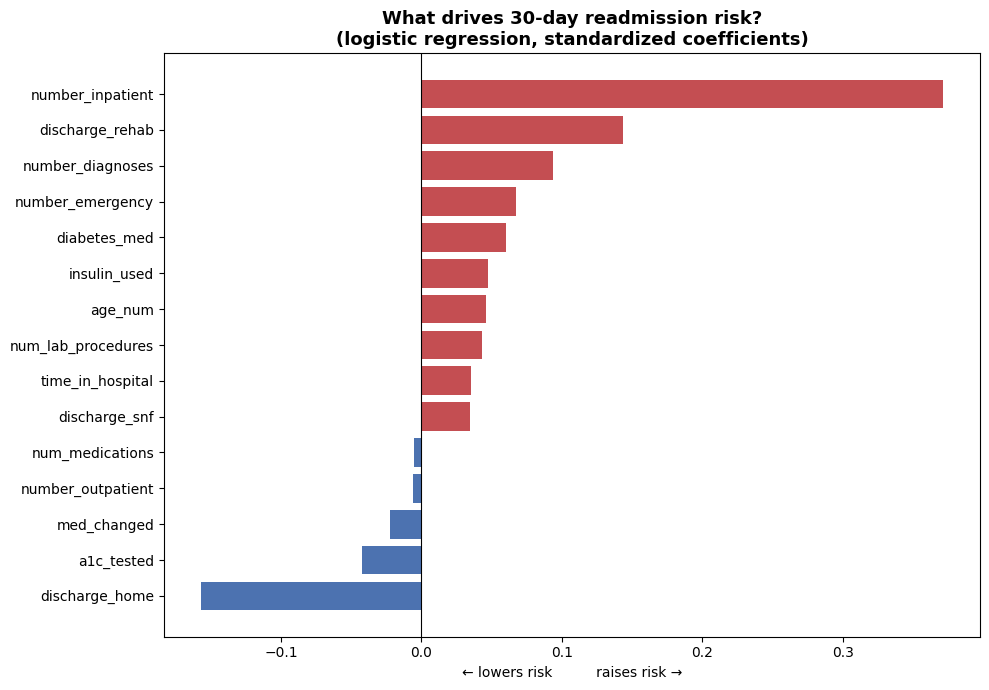

number_inpatient      0.371
discharge_rehab       0.144
number_diagnoses      0.094
number_emergency      0.067
diabetes_med          0.060
insulin_used          0.048
age_num               0.046
num_lab_procedures    0.043
time_in_hospital      0.036
discharge_snf         0.035
num_medications      -0.005
number_outpatient    -0.006
med_changed          -0.022
a1c_tested           -0.042
discharge_home       -0.157
dtype: float64


In [5]:
# Коэффициенты модели (признаки стандартизированы, поэтому их можно сравнивать между собой)
coefs = pd.Series(model.named_steps['logisticregression'].coef_[0], index=features).sort_values()

fig, ax = plt.subplots(figsize=(10, 7))
colors = ['#C44E52' if c > 0 else '#4C72B0' for c in coefs]
ax.barh(coefs.index, coefs.values, color=colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('What drives 30-day readmission risk?\n(logistic regression, standardized coefficients)',
             fontsize=13, fontweight='bold')
ax.set_xlabel('← lowers risk          raises risk →')
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

print(coefs.sort_values(ascending=False).round(3))

In [6]:
# Оценка риска моделью для каждой госпитализации
m['risk_score'] = model.predict_proba(X)[:, 1]

# Группы риска по процентилям: 50% / 30% / 10% / топ-10%
m['risk_group'] = pd.qcut(m['risk_score'], q=[0, 0.5, 0.8, 0.9, 1.0],
                          labels=['1 Low', '2 Medium', '3 High', '4 Very high'])

# Понятные названия мест выписки
discharge_names = {1: 'Home', 6: 'Home with home health', 3: 'Skilled nursing facility',
                   22: 'Rehab facility', 2: 'Another hospital', 5: 'Other inpatient facility',
                   4: 'Intermediate care facility', 7: 'Left against medical advice'}
m['discharge_to'] = m['discharge_disposition_id'].map(discharge_names).fillna('Other / unknown')

# Только нужные для дашборда колонки
export_cols = ['encounter_id', 'patient_nbr', 'age', 'gender', 'race',
               'time_in_hospital', 'num_medications', 'med_group',
               'number_inpatient', 'prior_inpatient', 'number_diagnoses',
               'A1Cresult', 'insulin', 'discharge_to',
               'readmitted_30d', 'risk_score', 'risk_group']
m[export_cols].to_csv('readmission_dashboard_data.csv', index=False)

print(m[export_cols].shape)
print(m.groupby('risk_group', observed=True)['readmitted_30d'].agg(['count', 'mean']).round(3))

# Скачать файл на компьютер
from google.colab import files
files.download('readmission_dashboard_data.csv')

(99340, 17)
             count   mean
risk_group               
1 Low        49670  0.069
2 Medium     29802  0.127
3 High        9934  0.156
4 Very high   9934  0.256


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>